## 1. Bibliotecas e FCM Puro

Versão local para **VS Code**, derivada do notebook K-Means apresentado pela equipe.
As 11 células e as seções 1–7 foram mantidas. O núcleo abaixo é a transcrição
oficial já auditada em `src/fcm_baseline.py`, sem Loop Unrolling e sem prints.
O `FCM_PURO.py` recebido, que contém logs, permanece intacto em `originais/`.
`segmenta_imagem()` agora recebe uma lista de pixels RGB e retorna `(C, U)`.


In [ ]:
%matplotlib inline
import os
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.optimize import curve_fit

# ==========================================
# 1. Função do Aluno (FCM Puro, sem unrolling)
# ==========================================
import random

def fcm_puro(X, K, m=2.0, max_iter=100, epsilon=0.01):
    """
    Implementacao FCM "Puro" (Baseline) sem bibliotecas avancadas
    ou funcoes escuras (utilizado por todas as equipes como base).
    X: Imagem (Lista de pixels, onde cada pixel e [R, G, B])
    K: Numero de clusters
    m: Fator de fuzzificacao (padrao 2.0)
    """
    N = len(X)
    canais = len(X[0]) # Tipicamente 3 (RGB)

    # FASE 1: INICIALIZACAO DA MATRIZ DE PERTINENCIA (U)
    U = []
    for i in range(N):
        linha = []
        soma_linha = 0.0

        for j in range(K):
            val = random.random()
            linha.append(val)
            soma_linha += val

        for j in range(K):
            linha[j] = linha[j] / soma_linha

        U.append(linha)

    # LACO PRINCIPAL DO FCM
    for iteracao in range(max_iter):

        # FASE 2: ATUALIZACAO DOS CENTROIDES
        C = []
        for j in range(K):
            numerador = [0.0] * canais
            denominador = 0.0

            for i in range(N):
                u_m = U[i][j] ** m
                denominador += u_m

                for c in range(canais):
                    numerador[c] += u_m * X[i][c]

            centroide_j = []
            for c in range(canais):
                centroide_j.append(numerador[c] / denominador)
            C.append(centroide_j)

        # FASE 3 E 4: ASSOCIACAO (DISTANCIA) E CONVERGENCIA
        U_nova = []
        max_diff = 0.0

        for i in range(N):
            linha_nova = [0.0] * K
            distancias = [0.0] * K

            for j in range(K):
                soma_quadrados = 0.0
                for c in range(canais):
                    diff = X[i][c] - C[j][c]
                    soma_quadrados += diff * diff

                distancias[j] = soma_quadrados ** 0.5

            for j in range(K):
                if distancias[j] == 0.0:
                    linha_nova[j] = 1.0
                    for k in range(K):
                        if k != j:
                            linha_nova[k] = 0.0
                    break

                soma_dist = 0.0
                for k in range(K):
                    razao = distancias[j] / distancias[k]
                    soma_dist += razao ** (2.0 / (m - 1.0))

                pertinencia = 1.0 / soma_dist
                linha_nova[j] = pertinencia

                diff_u = pertinencia - U[i][j]
                if diff_u < 0:
                    diff_u = -diff_u

                if diff_u > max_diff:
                    max_diff = diff_u

            U_nova.append(linha_nova)

        U = U_nova

        if max_diff < epsilon:
            break

    return C, U


def segmenta_imagem(pixels_rgb, k):
    """FCM completo: inicialização de U, iterações e parada; retorna C e U."""
    return fcm_puro(pixels_rgb, K=k, m=2.0, max_iter=100, epsilon=0.01)


## Execução local e preservação do baseline

Selecionar no VS Code o kernel Python da `.venv` do projeto ou da pasta pai.
Não há upload ou dependência do Colab. A célula verifica o núcleo e registra
as bibliotecas locais. Todos os laços de canais do FCM Puro permanecem.


In [ ]:
import ast
import csv
import gc
import hashlib
import importlib.metadata
import inspect
import json
import platform
import random
import sys
from datetime import datetime
from zoneinfo import ZoneInfo
from IPython.display import display

sys.dont_write_bytecode = True
candidatos = [Path.cwd(), Path.cwd() / "FCM_Credito2_Missao4", Path.cwd().parent]
base_dir = next((p.resolve() for p in candidatos
                 if (p / "src/fcm_baseline.py").is_file()
                 and (p / "documentacao/imagens_autorizadas.json").is_file()), None)
if base_dir is None:
    raise FileNotFoundError("Abra o notebook dentro do projeto FCM_Credito2_Missao4 no VS Code.")

fonte_baseline = (base_dir / "src/fcm_baseline.py").read_text()
assert (base_dir / "src/fcm_baseline.py").read_bytes() == (base_dir / "originais/fcm_puro_transcrito_pdf.py").read_bytes()
# Confere a função carregada, sem reescrevê-la ou trocar os laços por NumPy.
assert ast.dump(ast.parse(inspect.getsource(fcm_puro)).body[0]) == ast.dump(ast.parse(fonte_baseline).body[1])
print("Execução local:", sys.executable)
print("Projeto:", base_dir)
print("Baseline oficial conferido; três laços RGB preservados; sem Loop Unrolling.")
print("GC automático ativo:", gc.isenabled(), "| limiares:", gc.get_threshold())


Execução local: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/.venv/bin/python
Projeto: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4
Baseline oficial conferido; três laços RGB preservados; sem Loop Unrolling.
GC automático ativo: True | limiares: (2000, 10, 10)


## 2. Descoberta e ordenação

Três fontes: `images.jpeg`, `images (1).jpeg` e `images (2).jpeg`, copiadas da
pasta original `ExperimentoImagens/minhas_imagens` para `minhas_imagens_fcm_puro/`
e verificadas por SHA-256. O conjunto de duas fontes usado nos ensaios antigos
continua intacto em `minhas_imagens/`.

Cada fonte gera cinco entradas RGB quadradas (lados 16, 24, 32, 48 e 64).
São **três fontes**, não quinze imagens independentes. A reamostragem LANCZOS
altera as proporções; o objetivo é custo computacional, não fidelidade visual.
K=[2,3,4], **R=30**: 3×5×3=45 séries, **1.350 chamadas FCM Puro**.
Cada fonte é analisada separadamente. A saída de cada execução fica em pasta nova.


In [ ]:
# ==========================================
# 2. Descoberta e Ordenação Ligeira (Sem estourar RAM)
# ==========================================
img_dir = base_dir / "minhas_imagens_fcm_puro"
k_list = [2, 3, 4]
R = 30  # Template oficial; não usar R pequeno para homologação.
lados = [16, 24, 32, 48, 64]
TIPO_COLETA = "coleta"  # O ensaio de validação separado é identificado como smoke.
SEED = 42
assert gc.isenabled(), "Reative o GC antes da coleta; este protocolo mantém GC automático ativo."
run_id = datetime.now(ZoneInfo("America/Bahia")).strftime("%Y%m%d_%H%M%S_%f")
saida_dir = base_dir / "resultados/fcm_puro_notebook" / f"{TIPO_COLETA}_{run_id}"
saida_dir.mkdir(parents=True, exist_ok=False)
df_raw = pd.DataFrame()  # Evita usar dados antigos caso uma nova coleta seja interrompida.

print("Mapeando as três fontes autorizadas e calculando n...")
autorizadas = json.loads((base_dir / "documentacao/fcm_puro_notebook/imagens_autorizadas.json").read_text())
nomes = {p.name for p in img_dir.iterdir() if p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff', '.webp'}}
assert nomes == {p['arquivo'] for p in autorizadas}, "Use somente as três imagens autorizadas."
arquivos_n = []
for fonte in autorizadas:
    filepath = img_dir / fonte['arquivo']
    assert hashlib.sha256(filepath.read_bytes()).hexdigest() == fonte['sha256']
    with Image.open(filepath) as img:
        w, h = img.size
    for lado in lados:
        arquivos_n.append({'arquivo': fonte['arquivo'], 'imagem_id': fonte['id'],
                           'caminho': filepath, 'n': lado * lado, 'lado': lado,
                           'largura_original': w, 'altura_original': h})
arquivos_n = sorted(arquivos_n, key=lambda x: (x['n'], x['imagem_id']))
print(f"{len(arquivos_n)} entradas: {len(autorizadas)} fontes; n variados; K={k_list}; R={R}.")
print("Saída preservada em:", saida_dir)

ambiente = {'data_inicio': datetime.now(ZoneInfo('America/Bahia')).isoformat(),
    'tipo': TIPO_COLETA, 'algoritmo': 'FCM Puro oficial, sem unrolling',
    'python': sys.version, 'executavel': sys.executable, 'sistema': platform.platform(),
    'maquina': platform.machine(), 'energia': 'não aferido', 'R': R, 'K': k_list,
    'lados': lados, 'seed': SEED, 'm': 2.0, 'epsilon': 0.01, 'max_iter': 100,
    'fontes': [{k: v for k, v in p.items() if k != 'origem'} for p in autorizadas],
    'baseline_sha256': hashlib.sha256(fonte_baseline.encode()).hexdigest(),
    'gc_automatico': gc.isenabled(), 'gc_limiares': gc.get_threshold(),
    'preparo': 'liberar C/U anteriores; gc.collect() e random.seed(42) antes de t0; aquecimento por caso',
    'conversao': 'RGB, LANCZOS, AoS de floats fora do timer',
    'timer': 'perf_counter envolvendo segmenta_imagem(X,k), chamada FCM completa',
    'dependencias': {p: importlib.metadata.version(p) for p in ['numpy', 'scipy', 'pandas', 'matplotlib', 'Pillow', 'ipykernel']}}
(saida_dir / 'ambiente.json').write_text(json.dumps(ambiente, indent=2, ensure_ascii=False))


Mapeando as três fontes autorizadas e calculando n...
15 entradas: 3 fontes; n variados; K=[2, 3, 4]; R=30.
Saída preservada em: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287


1640

## 3. Medição real do FCM completo

Leitura, RGB, redimensionamento e conversão para `[[R,G,B], ...]` ficam fora
do cronômetro. A seed é reaplicada antes de cada chamada. O timer inclui toda
a inicialização e todas as iterações do FCM.

Antes de cada chamada, o resultado anterior é liberado e `gc.collect()` é
executado **fora do timer**. O GC automático permanece ativo durante o FCM.
Isso padroniza o estado de memória, sem mudar a lógica do algoritmo ou editar
amostras. Este é um novo protocolo documentado; não comparar seus tempos
com a variante anterior como se ambos tivessem o mesmo preparo.

Há um aquecimento não medido por caso. Nenhum callback/tracing, print ou plot
fica dentro do timer. Todos os tempos individuais são gravados imediatamente.
As segmentações e a validação de C/U ocorrem depois das 30 repetições do caso.


images.jpeg: n=256, K=2, R=30, CV filtrado=0.016772


images.jpeg: n=256, K=3, R=30, CV filtrado=0.011584


images.jpeg: n=256, K=4, R=30, CV filtrado=0.007080
Entrada images.jpeg, n=256, concluída.


images (1).jpeg: n=256, K=2, R=30, CV filtrado=0.014701


images (1).jpeg: n=256, K=3, R=30, CV filtrado=0.012144


...

images (1).jpeg: n=576, K=4, R=30, CV filtrado=0.004908
Entrada images (1).jpeg, n=576, concluída.


images (2).jpeg: n=576, K=2, R=30, CV filtrado=0.007822


images (2).jpeg: n=576, K=3, R=30, CV filtrado=0.009249


images (2).jpeg: n=576, K=4, R=30, CV filtrado=0.003348
Entrada images (2).jpeg, n=576, concluída.


images.jpeg: n=1024, K=2, R=30, CV filtrado=0.008980


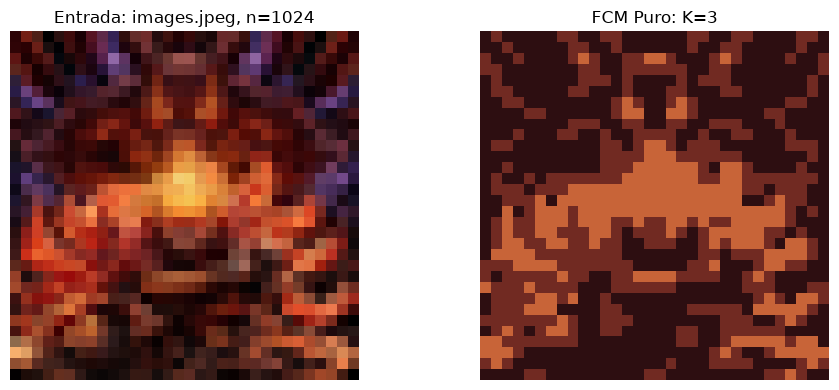

images.jpeg: n=1024, K=3, R=30, CV filtrado=0.008939


images.jpeg: n=1024, K=4, R=30, CV filtrado=0.018779
Entrada images.jpeg, n=1024, concluída.


images (1).jpeg: n=1024, K=2, R=30, CV filtrado=0.005829


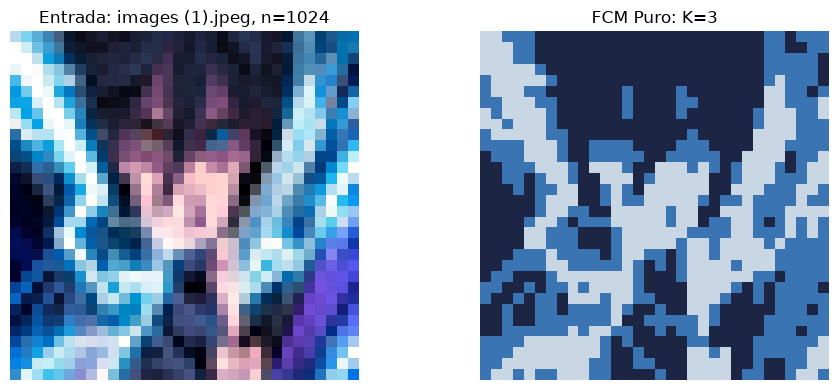

images (1).jpeg: n=1024, K=3, R=30, CV filtrado=0.005764


images (1).jpeg: n=1024, K=4, R=30, CV filtrado=0.016241
Entrada images (1).jpeg, n=1024, concluída.


images (2).jpeg: n=1024, K=2, R=30, CV filtrado=0.010413


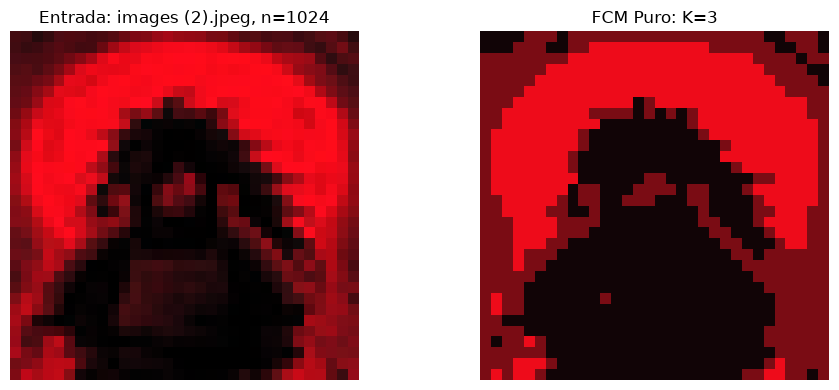

images (2).jpeg: n=1024, K=3, R=30, CV filtrado=0.004687


images (2).jpeg: n=1024, K=4, R=30, CV filtrado=0.003803
Entrada images (2).jpeg, n=1024, concluída.


images.jpeg: n=2304, K=2, R=30, CV filtrado=0.005189


images.jpeg: n=2304, K=3, R=30, CV filtrado=0.003107


images.jpeg: n=2304, K=4, R=30, CV filtrado=0.005138
Entrada images.jpeg, n=2304, concluída.


...

images (1).jpeg: n=4096, K=3, R=30, CV filtrado=0.004290


images (1).jpeg: n=4096, K=4, R=30, CV filtrado=0.003970
Entrada images (1).jpeg, n=4096, concluída.


images (2).jpeg: n=4096, K=2, R=30, CV filtrado=0.004528


images (2).jpeg: n=4096, K=3, R=30, CV filtrado=0.002182


images (2).jpeg: n=4096, K=4, R=30, CV filtrado=0.008491
Entrada images (2).jpeg, n=4096, concluída.
1350 tempos FCM Puro realmente medidos, preservados em /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/tempos_brutos_fcm_puro.csv


In [ ]:
# ==========================================
# 3. Execução (Carregando sob demanda)
# ==========================================
if len({item['n'] for item in arquivos_n}) < 2:
    raise ValueError("Use pelo menos dois tamanhos diferentes para ajustar a curva.")
resultados = []
raw_path = saida_dir / 'tempos_brutos_fcm_puro.csv'
with raw_path.open('w', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=['arquivo', 'imagem_id', 'n', 'k', 'repeticao', 'tempo'], delimiter=';')
    writer.writeheader()
    for item in arquivos_n:
        n, filepath, nome_arquivo = item['n'], item['caminho'], item['arquivo']
        # Carrega e prepara a imagem fora do intervalo cronometrado.
        with Image.open(filepath) as img:
            img_array = np.array(img.convert('RGB').resize((item['lado'], item['lado']), Image.Resampling.LANCZOS))
        X = img_array.reshape(-1, 3).astype(float).tolist()
        assert len(X) == n and all(len(pixel) == 3 for pixel in X)
        destino_imagem = saida_dir / item['imagem_id']
        destino_imagem.mkdir(exist_ok=True)
        Image.fromarray(img_array).save(destino_imagem / f"entrada_{item['lado']}.png")
        for k in k_list:
            # Aquecimento fora do timer, sem alterar o núcleo ou seus parâmetros.
            random.seed(SEED)
            segmenta_imagem(X, k)
            for r in range(R):
                if 'centroides' in globals():
                    del centroides, matriz_u
                gc.collect()
                random.seed(SEED)
                t0 = time.perf_counter()
                centroides, matriz_u = segmenta_imagem(X, k)
                t1 = time.perf_counter()
                medida = {'arquivo': nome_arquivo, 'imagem_id': item['imagem_id'],
                          'n': n, 'k': k, 'repeticao': r, 'tempo': t1 - t0}
                resultados.append(medida)
                writer.writerow(medida)
                stream.flush()
            # Inspeção funcional e reconstrução visual fora do timer.
            U_array = np.asarray(matriz_u)
            assert U_array.shape == (n, k)
            assert np.isfinite(centroides).all() and np.isfinite(U_array).all()
            assert ((U_array >= 0) & (U_array <= 1)).all()
            assert np.allclose(U_array.sum(axis=1), 1, rtol=0, atol=1e-12)
            rotulos = U_array.argmax(axis=1)
            img_segmentada = np.rint(np.asarray(centroides)[rotulos]).clip(0, 255).astype(np.uint8).reshape(img_array.shape)
            fig_seg, axes = plt.subplots(1, 2, figsize=(10, 4))
            axes[0].imshow(img_array)
            axes[0].set_title(f"Entrada: {nome_arquivo}, n={n}")
            axes[1].imshow(img_segmentada)
            axes[1].set_title(f"FCM Puro: K={k}")
            for ax in axes:
                ax.axis('off')
            fig_seg.tight_layout()
            fig_seg.savefig(destino_imagem / f"n{n}_k{k}_comparacao.png", dpi=150)
            if item['lado'] == 32 and k == 3:
                display(fig_seg)
            plt.close(fig_seg)
            tempos_caso = pd.Series([v['tempo'] for v in resultados
                                    if v['imagem_id'] == item['imagem_id'] and v['n'] == n and v['k'] == k])
            p5, p95 = tempos_caso.quantile([0.05, 0.95])
            validos = tempos_caso[tempos_caso.between(p5, p95)]
            print(f"{nome_arquivo}: n={n}, K={k}, R={R}, CV filtrado={validos.std(ddof=1)/validos.mean():.6f}")
        del img_array, img_segmentada, X, U_array
        print(f"Entrada {nome_arquivo}, n={n}, concluída.")

df_raw = pd.DataFrame(resultados)
ambiente['data_fim_coleta'] = datetime.now(ZoneInfo('America/Bahia')).isoformat()
ambiente['chamadas_medidas'] = len(df_raw)
(saida_dir / 'ambiente.json').write_text(json.dumps(ambiente, indent=2, ensure_ascii=False))
print(f"{len(df_raw)} tempos FCM Puro realmente medidos, preservados em {raw_path}")


## 4 a 7. Estatísticas, ajuste, gráficos e exportação

Mantidas as seções do notebook apresentado: P5–P95 inclusivo, média,
desvio **amostral**, CV **estritamente <0,15**, `curve_fit`, gráficos tempo×n,
tempo×K, superfície 3D e CSV. As fontes são analisadas separadamente para não
misturar 60 amostras de conteúdos distintos em um mesmo grupo n/K.

Um resultado é homologado somente com R=30 e CV filtrado <0,15; todas as
falhas continuam visíveis. Se houver reprovação, guardar a coleta e realizar
um novo ensaio completo em outra pasta, sem selecionar ou editar amostras.



--- Resumo de Estabilidade ---
       n  k  tempo_medio    desvio  contagem_valida        CV  \
0    256  2     0.003513  0.000059               26  0.016772   
1    256  3     0.006699  0.000078               26  0.011584   
2    256  4     0.008299  0.000059               26  0.007080   
3    576  2     0.007087  0.000065               26  0.009147   
4    576  3     0.015532  0.000091               26  0.005836   
5    576  4     0.032727  0.000158               26  0.004825   
6   1024  2     0.012879  0.000116               26  0.008980   
7   1024  3     0.022380  0.000200               26  0.008939   
8   1024  4     0.064376  0.001209               26  0.018779   
9   2304  2     0.026474  0.000137               26  0.005189   
10  2304  3     0.058766  0.000183               26  0.003107   
11  2304  4     0.108421  0.000557               26  0.005138   
12  4096  2     0.052112  0.000275               26  0.005281   
13  4096  3     0.126792  0.000349               26  0.002

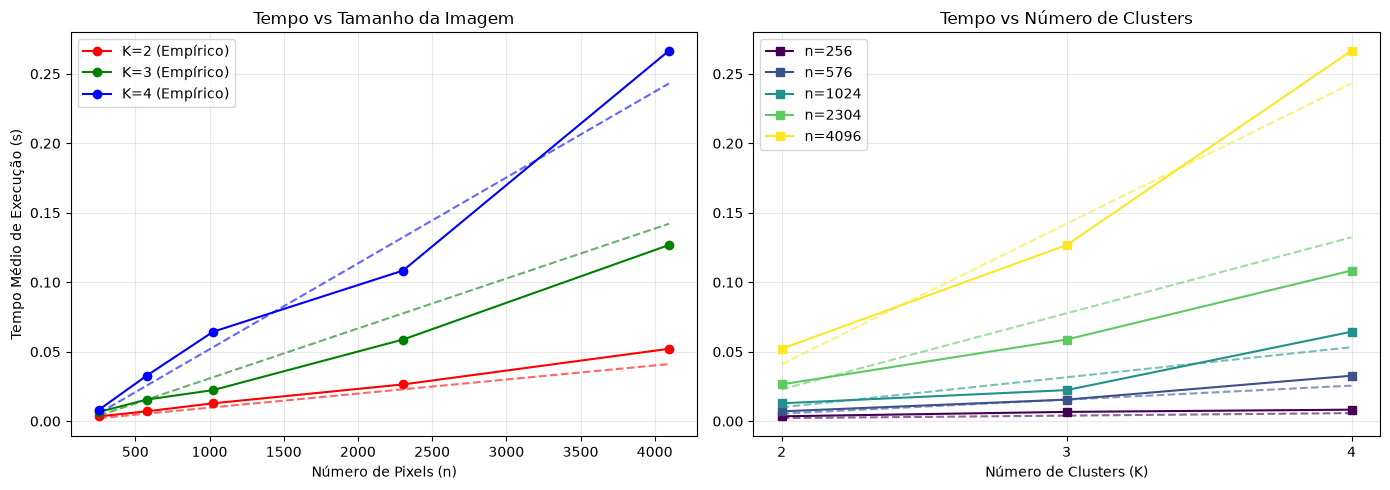

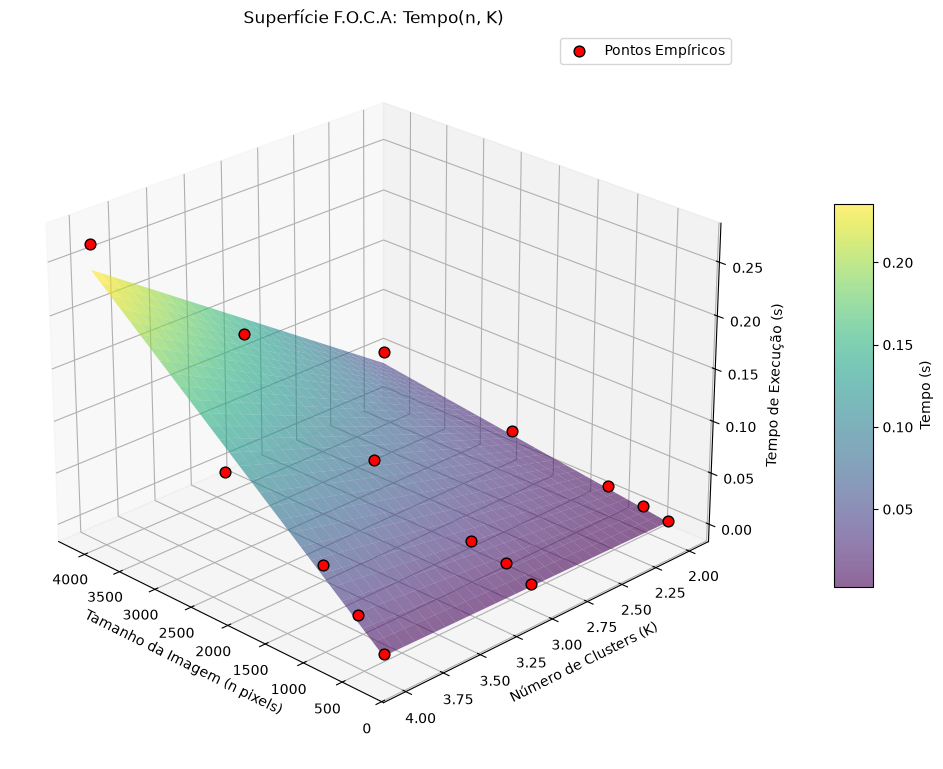


Pipeline concluído. Gráficos gerados e salvos em: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_01/relatorio_complexidade.png e /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_01/superficie_3d_foca.png
Tabela de avaliação exportada com sucesso para: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_01/resultados_foca_aluno.csv

--- Resumo de Estabilidade ---
       n  k  tempo_medio    desvio  contagem_valida        CV  \
0    256  2     0.002226  0.000033               26  0.014701   
1    256  3     0.004011  0.000049               26  0.012144   
2    256  4     0.012259  0.000101               26  0.008234   
3    576  2     0.005908  0.000051               26  0.008713   
4    576  3     0.0

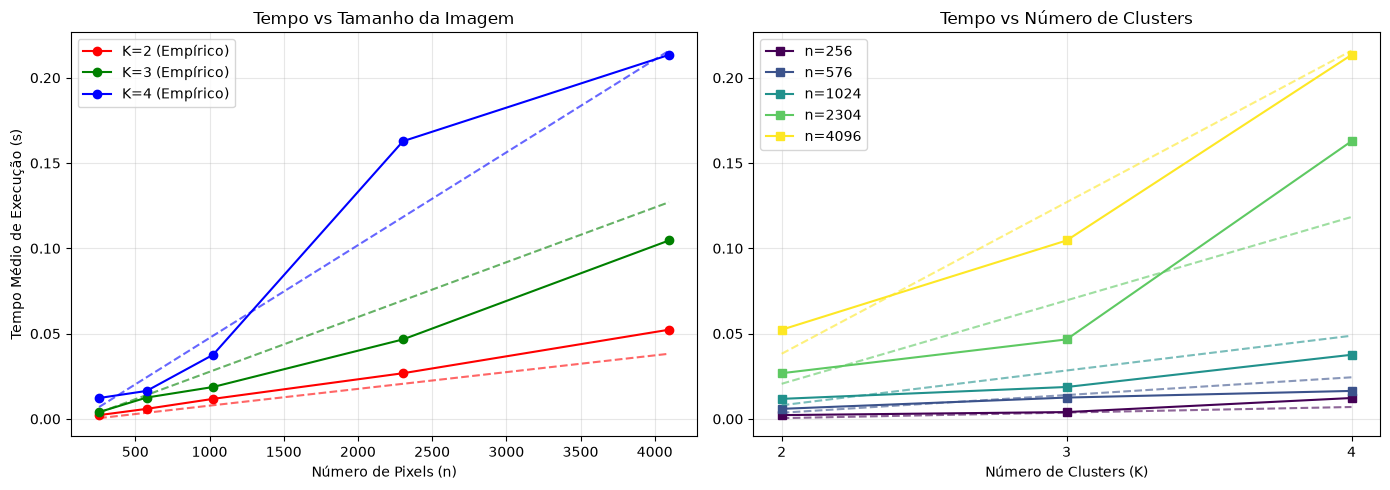

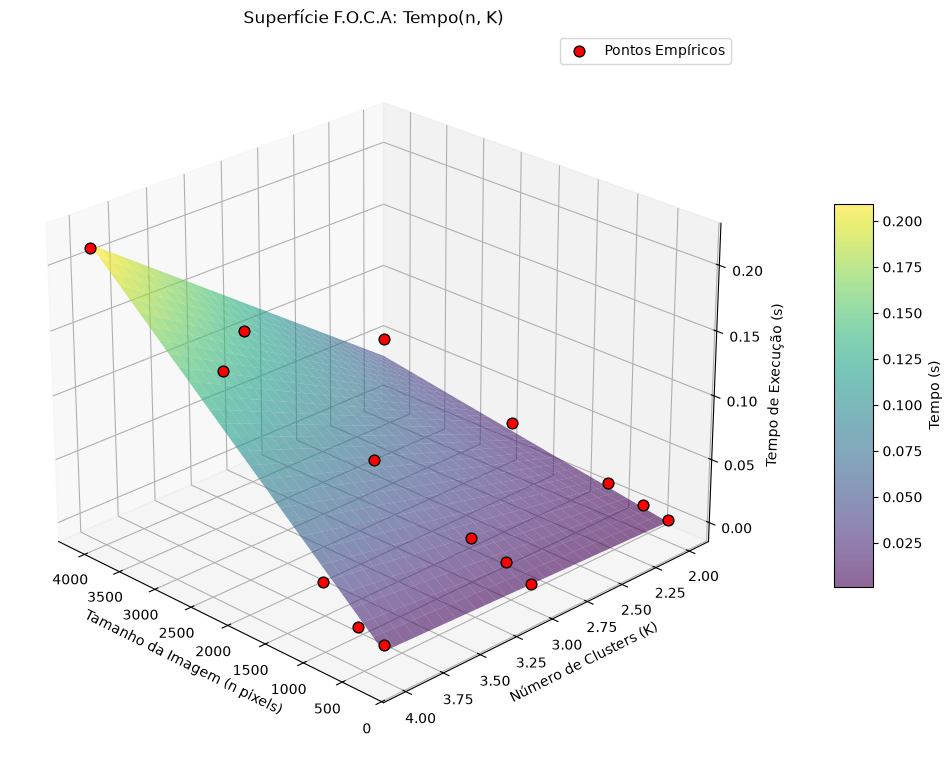


Pipeline concluído. Gráficos gerados e salvos em: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_02/relatorio_complexidade.png e /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_02/superficie_3d_foca.png
Tabela de avaliação exportada com sucesso para: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_02/resultados_foca_aluno.csv

--- Resumo de Estabilidade ---
       n  k  tempo_medio    desvio  contagem_valida        CV  \
0    256  2     0.001960  0.000029               26  0.014730   
1    256  3     0.005399  0.000049               26  0.009049   
2    256  4     0.007820  0.000062               26  0.007904   
3    576  2     0.005253  0.000041               26  0.007822   
4    576  3     0.0

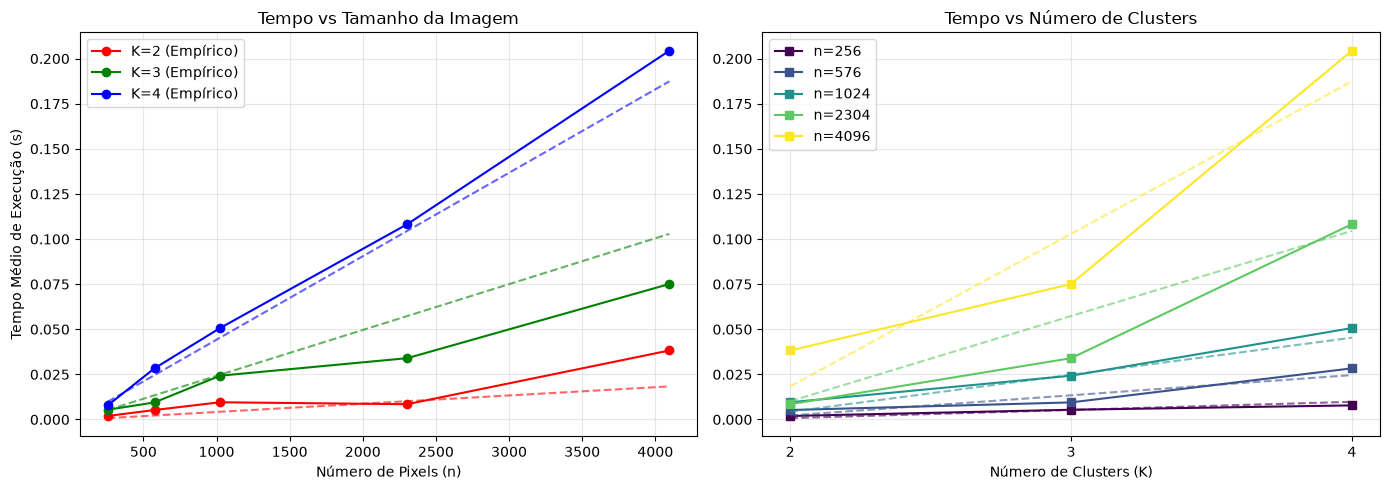

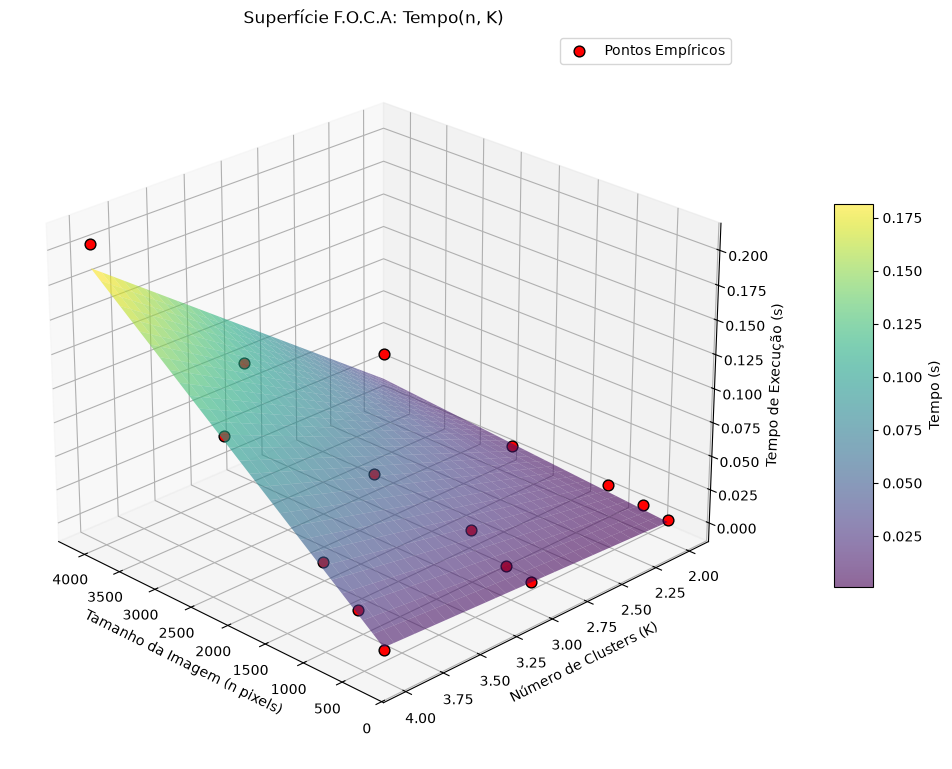


Pipeline concluído. Gráficos gerados e salvos em: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_03/relatorio_complexidade.png e /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_03/superficie_3d_foca.png
Tabela de avaliação exportada com sucesso para: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287/imagem_03/resultados_foca_aluno.csv

HOMOLOGAÇÃO: 45/45 séries; CV estrito <0.15 e R=30.


,arquivo,n,k,contagem_bruta,contagem_valida,tempo_medio,desvio,CV,status
0,images.jpeg,256,2,30,26,0.003513,0.000059,0.016772,HOMOLOGADA
1,images.jpeg,256,3,30,26,0.006699,0.000078,0.011584,HOMOLOGADA
2,images.jpeg,256,4,30,26,0.008299,0.000059,0.007080,HOMOLOGADA
3,images.jpeg,576,2,30,26,0.007087,0.000065,0.009147,HOMOLOGADA
4,images.jpeg,576,3,30,26,0.015532,0.000091,0.005836,HOMOLOGADA
5,images.jpeg,576,4,30,26,0.032727,0.000158,0.004825,HOMOLOGADA
6,images.jpeg,1024,2,30,26,0.012879,0.000116,0.008980,HOMOLOGADA
7,images.jpeg,1024,3,30,26,0.022380,0.000200,0.008939,HOMOLOGADA
8,images.jpeg,1024,4,30,26,0.064376,0.001209,0.018779,HOMOLOGADA
9,images.jpeg,2304,2,30,26,0.026474,0.000137,0.005189,HOMOLOGADA


Todas as séries desta coleta FCM Puro foram estatisticamente homologadas.
Pasta desta execução: /Users/_rssantana/Developer/UniSolves/EngenariadeProgramas/FCM_Credito2_Missao4/resultados/fcm_puro_notebook/coleta_20261027_083247_010287


In [ ]:
# ==========================================
# 4. Pré-processamento e Validação F.O.C.A.
# ==========================================
if df_raw.empty:
    raise ValueError('Execute a célula de medição antes da análise.')
resumos = []
for imagem_id, df_imagem in df_raw.groupby('imagem_id', sort=True):
    destino_imagem = saida_dir / imagem_id
    df_filtered = pd.DataFrame()

    # Filtragem de Outliers (Percentis 5 e 95)
    for (n, k), group in df_imagem.groupby(['n', 'k']):
        p05 = group['tempo'].quantile(0.05)
        p95 = group['tempo'].quantile(0.95)
        valid_mask = (group['tempo'] >= p05) & (group['tempo'] <= p95)
        df_filtered = pd.concat([df_filtered, group[valid_mask]])

    # Validação de Estabilidade (Média, Desvio e CV)
    resumo = df_filtered.groupby(['n', 'k']).agg(
        tempo_medio=('tempo', 'mean'),
        desvio=('tempo', 'std'),
        contagem_valida=('tempo', 'count')
    ).reset_index()

    resumo['CV'] = resumo['desvio'] / resumo['tempo_medio']
    resumo['estavel_CV_menor_15'] = resumo['CV'] < 0.15

    print("\n--- Resumo de Estabilidade ---")
    print(resumo)

    # Contagens, filtradas e status são preservados antes do ajuste.
    contagens = df_imagem.groupby(['n', 'k']).size().reset_index(name='contagem_bruta')
    resumo = resumo.merge(contagens, on=['n', 'k'])
    resumo['taxa_descarte'] = 1 - resumo['contagem_valida'] / resumo['contagem_bruta']
    resumo['homologada'] = resumo['estavel_CV_menor_15'] & (resumo['contagem_bruta'] == 30) & (TIPO_COLETA == 'coleta')
    resumo['status'] = np.where(resumo['homologada'], 'HOMOLOGADA', 'NAO HOMOLOGADA')
    resumo['imagem_id'] = imagem_id
    resumo['arquivo'] = df_imagem['arquivo'].iloc[0]
    df_filtered.to_csv(destino_imagem / 'tempos_filtrados.csv', index=False, sep=';')
    resumo.to_csv(destino_imagem / 'validacao_cv.csv', index=False, sep=';', decimal=',')
    print(f"\nFonte: {resumo['arquivo'].iloc[0]} | {int(resumo.homologada.sum())}/{len(resumo)} homologadas")
    if not resumo.homologada.all():
        print('ATENCAO: ajuste exploratorio; ha series NAO HOMOLOGADAS.')

    # ==========================================
    # 5. Ajuste de Curvas
    # ==========================================
    def model_n_k(X, alpha, beta, gamma, delta):
        n, k = X
        return alpha * (n * k) + beta * n + gamma * k + delta

    def exibir_equacao_ajustada(popt, X_data, y_data):
        """
        Exibe no terminal a equação ajustada com notação científica legível,
        os coeficientes individuais e o coeficiente de determinação (R²).
        """
        alpha, beta, gamma, delta = popt

        # Cálculo do R² (Coeficiente de Determinação)
        y_pred = model_n_k(X_data, *popt)
        ss_res = np.sum((y_data - y_pred) ** 2)
        ss_tot = np.sum((y_data - np.mean(y_data)) ** 2)
        r2 = 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

        print("\n" + "=" * 60)
        print("   MODELO EMPÍRICO AJUSTADO: T(n, K)")
        print("=" * 60)
        print("Formulação Geral:")
        print("  T(n, K) = α·(n·K) + β·n + γ·K + δ\n")
        print("Parâmetros Identificados:")
        print(f"  α (alpha) = {alpha:14.6e} s/(pixel·cluster)")
        print(f"  β (beta)  = {beta:14.6e} s/pixel")
        print(f"  γ (gamma) = {gamma:14.6e} s/cluster")
        print(f"  δ (delta) = {delta:14.6e} s (overhead base)")
        print("-" * 60)
        print("Equação Parametrizada:")
        print(f"  T(n, K) = ({alpha:.4e})·(n·K) + ({beta:.4e})·n + ({gamma:.4e})·K + ({delta:.4e})")
        print(f"Aderência Estatística (R²): {r2:.4f}")
        print("=" * 60 + "\n")

    X_data = np.vstack((resumo['n'], resumo['k']))
    y_data = resumo['tempo_medio']

    # O p0 pode precisar de sintonia dependendo da escala de tempo real
    popt, _ = curve_fit(model_n_k, X_data, y_data, p0=[1e-6, 1e-6, 1e-6, 0.01], maxfev=10000)
    resumo['tempo_predito'] = model_n_k(X_data, *popt)

    exibir_equacao_ajustada(popt, X_data, y_data)

    # ==========================================
    # 6. Plotagens Bidimensionais
    # ==========================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Plot A: Tempo vs n
    colors_k = ['red', 'green', 'blue', 'orange', 'purple']
    for idx, k in enumerate(k_list):
        dados_k = resumo[resumo['k'] == k]
        if not dados_k.empty:
            c = colors_k[idx % len(colors_k)]
            ax1.plot(dados_k['n'], dados_k['tempo_medio'], marker='o',
                     color=c, label=f'K={k} (Empírico)')
            ax1.plot(dados_k['n'], dados_k['tempo_predito'], linestyle='--',
                     color=c, alpha=0.6)

    ax1.set_xlabel('Número de Pixels (n)')
    ax1.set_ylabel('Tempo Médio de Execução (s)')
    ax1.set_title('Tempo vs Tamanho da Imagem')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Plot B: Tempo vs K
    n_processados = sorted(resumo['n'].unique())
    colors_n = plt.cm.viridis(np.linspace(0, 1, len(n_processados)))

    for idx, n_val in enumerate(n_processados):
        dados_n = resumo[resumo['n'] == n_val]
        if not dados_n.empty:
            ax2.plot(dados_n['k'], dados_n['tempo_medio'], marker='s',
                     color=colors_n[idx], label=f'n={n_val}')
            ax2.plot(dados_n['k'], dados_n['tempo_predito'], linestyle='--',
                     color=colors_n[idx], alpha=0.6)

    ax2.set_xlabel('Número de Clusters (K)')
    ax2.set_title('Tempo vs Número de Clusters')
    ax2.set_xticks(k_list)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    arquivo_grafico = destino_imagem / 'relatorio_complexidade.png'
    plt.savefig(arquivo_grafico, dpi=300)
    plt.show()
    plt.close('all')

    # ==========================================
    # 6.5. Plotagem da Superfície 3D (Tempo vs n, k)
    # ==========================================
    fig_3d = plt.figure(figsize=(10, 8))
    ax_3d = fig_3d.add_subplot(111, projection='3d')

    # Cria uma malha contínua baseada nos limites reais dos dados
    n_linspace = np.linspace(resumo['n'].min(), resumo['n'].max(), 30)
    k_linspace = np.linspace(resumo['k'].min(), resumo['k'].max(), 30)
    N_mesh, K_mesh = np.meshgrid(n_linspace, k_linspace)

    # Aplica a equação ajustada em todos os pontos da malha
    T_mesh = model_n_k((N_mesh, K_mesh), *popt)

    # Desenha a superfície teórica translúcida
    surf = ax_3d.plot_surface(N_mesh, K_mesh, T_mesh, cmap='viridis', alpha=0.6,
                              linewidth=0.1, antialiased=True)
    fig_3d.colorbar(surf, ax=ax_3d, shrink=0.5, aspect=10, pad=0.1, label='Tempo (s)')

    # Sobrepõe os pontos empíricos medidos
    ax_3d.scatter(resumo['n'], resumo['k'], resumo['tempo_medio'],
                  color='red', edgecolor='black', s=60, label='Pontos Empíricos', depthshade=False)

    ax_3d.set_xlabel('Tamanho da Imagem (n pixels)')
    ax_3d.set_ylabel('Número de Clusters (K)')
    ax_3d.set_zlabel('Tempo de Execução (s)')
    ax_3d.set_title('Superfície F.O.C.A: Tempo(n, K)')
    ax_3d.view_init(elev=25, azim=135)
    ax_3d.legend()

    plt.tight_layout()
    arquivo_superficie = destino_imagem / 'superficie_3d_foca.png'
    fig_3d.savefig(arquivo_superficie, dpi=300)
    plt.show()
    plt.close('all')

    print(f"\nPipeline concluído. Gráficos gerados e salvos em: {arquivo_grafico} e {arquivo_superficie}")

    # ==========================================
    # 7. Exportação dos Dados para Avaliação
    # ==========================================
    arquivo_csv = destino_imagem / 'resultados_foca_aluno.csv'

    # Exporta os dados usando ponto e vírgula como separador e vírgula para decimais,
    # garantindo que o arquivo seja aberto corretamente no Excel em PT-BR.
    resumo.to_csv(arquivo_csv, index=False, sep=';', decimal=',')

    print(f"Tabela de avaliação exportada com sucesso para: {arquivo_csv}")

    resumo['residuo'] = y_data - resumo['tempo_predito']
    resumo.to_csv(destino_imagem / 'resultados_foca_aluno.csv', index=False, sep=';', decimal=',')
    r2 = 1 - float(np.sum((y_data - resumo['tempo_predito'])**2) / np.sum((y_data - np.mean(y_data))**2))
    (destino_imagem / 'ajuste.json').write_text(json.dumps({
        'modelo': 'alpha*n*K + beta*n + gamma*K + delta',
        'coeficientes': dict(zip(['alpha','beta','gamma','delta'], map(float, popt))),
        'r2': r2, 'todas_homologadas': bool(resumo.homologada.all()),
        'ressalva': 'Ajuste local; nao prova O(nK). O codigo contem O(I*n*K²).'
    }, indent=2, ensure_ascii=False))
    resumos.append(resumo)

resumo_completo = pd.concat(resumos, ignore_index=True)
resumo_completo.to_csv(saida_dir / 'resultados_foca_aluno.csv', index=False, sep=';', decimal=',')
falhas = resumo_completo[~resumo_completo.homologada]
print(f"\nHOMOLOGAÇÃO: {int(resumo_completo.homologada.sum())}/{len(resumo_completo)} séries; CV estrito <0.15 e R=30.")
display(resumo_completo[['arquivo','n','k','contagem_bruta','contagem_valida','tempo_medio','desvio','CV','status']])
if not falhas.empty:
    print('NAO DECLARAR HOMOLOGACAO COMPLETA. Preservar esta coleta e diagnosticar:')
    display(falhas[['arquivo','n','k','CV','status']])
else:
    print('Todas as séries desta coleta FCM Puro foram estatisticamente homologadas.')
(saida_dir / 'homologacao.json').write_text(json.dumps({
    'algoritmo': 'FCM Puro sem unrolling', 'R': R, 'limite_CV_estrito': 0.15,
    'series': len(resumo_completo), 'aprovadas': int(resumo_completo.homologada.sum()),
    'todas_homologadas': bool(resumo_completo.homologada.all()),
    'medicoes': len(df_raw), 'pasta': saida_dir.name
}, indent=2, ensure_ascii=False))
print('Pasta desta execução:', saida_dir)


## Pontos para explicar no VS Code

- **Algoritmo:** somente FCM Puro oficial, sem Loop Unrolling. `segmenta_imagem()`
  chama o FCM completo e retorna C/U; não usa K-Means ou biblioteca FCM pronta.
- **Cronômetro:** inclui inicialização, centróides, pertinências e convergência.
  Conversão, seed, preparo de memória, console e figuras ficam fora.
- **Protocolo:** R=30, as três fontes autorizadas, mesma seed, cinco n, K=2/3/4;
  cada fonte é analisada separadamente. GC automático ativo e coleta explícita
  antes de cada chamada para padronizar memória; o baseline não foi alterado.
- **CV:** todas as combinações são verificadas individualmente. Consultar a
  tabela e `homologacao.json`; não presumir aprovação só por o código rodar.
- **Modelo:** T(n,K)=αnK+βn+γK+δ é o ajuste exigido; o código contém
  O(I·n·K²). R² não prova Big-O e I depende da convergência e do conteúdo.
- **Histórico:** resultados anteriores de Loop Unrolling continuam intactos
  em `resultados/coleta_duas_imagens_R30/`. O preparo de medição difere;
  uma comparação temporal direta exige protocolos equivalentes.
- **Execução em sala:** abrir este `.ipynb` no VS Code, selecionar a `.venv`
  e executar as células em ordem. As figuras e tabelas aparecem no próprio
  notebook e os CSVs/PNGs são salvos em uma pasta nova de `resultados/fcm_puro_notebook/`.
